In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Define hierarchical cluster order
cluster_order = [5, 4, 3, 2, 1]

# Define fixed colors for each cluster
cluster_colors = {
    1: "#2166AC",
    2: "#67A9CF",
    3: "#F7F7F7",
    4: "#EF8A62",
    5: "#B2182B",
}

# Optional: human-readable cluster names
cluster_names = {
    1: "Pre-transition",
    2: "Early transition",
    3: "Mid-transition",
    4: "Late-transition",
    5: "Post-transition"
}

# Basamak Profil

In [3]:
df = pd.read_csv("../data/out/g02_kume_merkezleri.csv")
df.head(10)

,cluster,cluster_name,tfr,lex,median_age,n_obs
0,1,Geçiş öncesi,6.71,42.30,17.27,2362
1,2,Erken geçiş,6.01,56.55,16.72,2668
2,3,Orta geçiş,3.71,65.16,19.89,2291
3,4,Geç geçiş,2.31,71.62,28.29,2843
4,5,Geçiş sonrası,1.54,77.10,37.48,1750


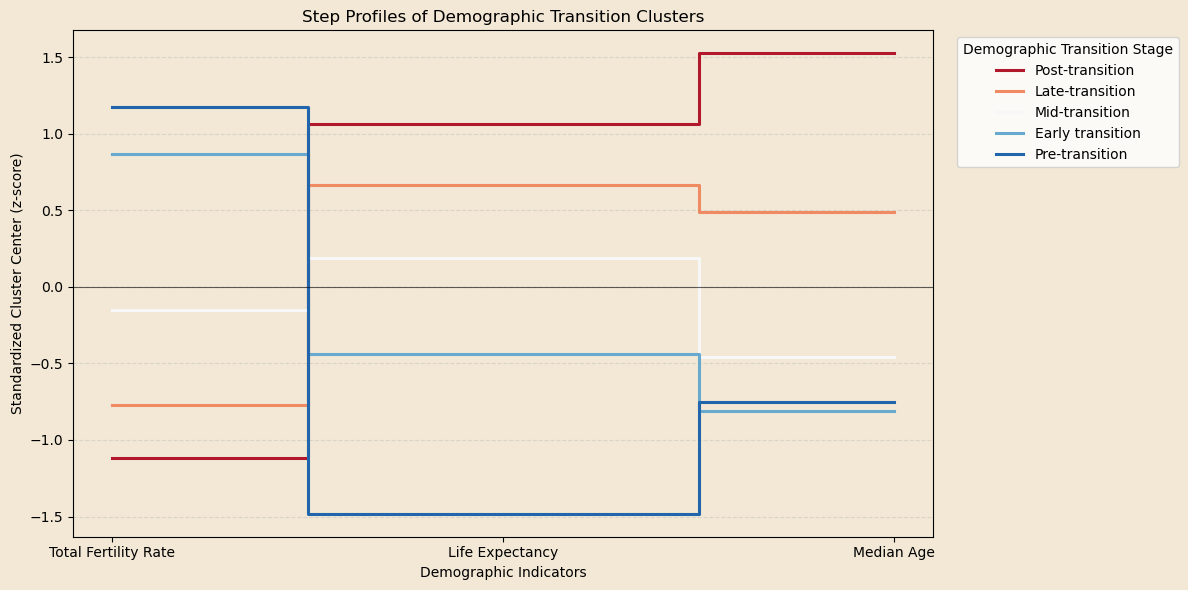

In [4]:
features = ["tfr", "lex", "median_age"]

# Convert numeric columns
df["cluster"] = pd.to_numeric(df["cluster"], errors="raise").astype(int)

for col in features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Sort clusters hierarchically
df = df.set_index("cluster").reindex(cluster_order).reset_index()

# Standardize indicators
means = df[features].mean()
stds = df[features].std().replace(0, 1)
df[features] = (df[features] - means) / stds

# Plot
fig, ax = plt.subplots(figsize=(12, 6))
fig.patch.set_facecolor("#F2E8D5")  # Figure background
ax.set_facecolor("#F2E8D5")         # Plot background

for _, row in df.iterrows():
    cluster = int(row["cluster"])

    ax.step(
        range(len(features)),
        row[features].values,
        where="mid",
        linewidth=2.2,
        color=cluster_colors[cluster],
        label=cluster_names[cluster]
    )

ax.set_xticks(range(len(features)))
ax.set_xticklabels([
    "Total Fertility Rate",
    "Life Expectancy",
    "Median Age"
])

ax.set_xlabel("Demographic Indicators")
ax.set_ylabel("Standardized Cluster Center (z-score)")
ax.set_title("Step Profiles of Demographic Transition Clusters")

ax.axhline(0, color="black", linewidth=0.8, alpha=0.6)
ax.grid(axis="y", linestyle="--", alpha=0.35)

ax.legend(
    title="Demographic Transition Stage",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.savefig("../charts/g02_step_profile.png", dpi=300, bbox_inches="tight")
plt.show()

# %100 Yığılmış

In [5]:
df = pd.read_csv("../data/out/g02_kume_dagilimi.csv")
df.head(10)

,year,cluster,cluster_name,n_countries,pop_millions
0,1950,1,Geçiş öncesi,93,1544.13
1,1950,2,Erken geçiş,22,96.67
2,1950,3,Orta geçiş,18,300.82
3,1950,4,Geç geçiş,28,545.78
4,1951,1,Geçiş öncesi,92,1520.13
5,1951,2,Erken geçiş,23,154.28
6,1951,3,Orta geçiş,18,305.61
7,1951,4,Geç geçiş,28,551.10
8,1952,1,Geçiş öncesi,89,1533.72
9,1952,2,Erken geçiş,25,175.43


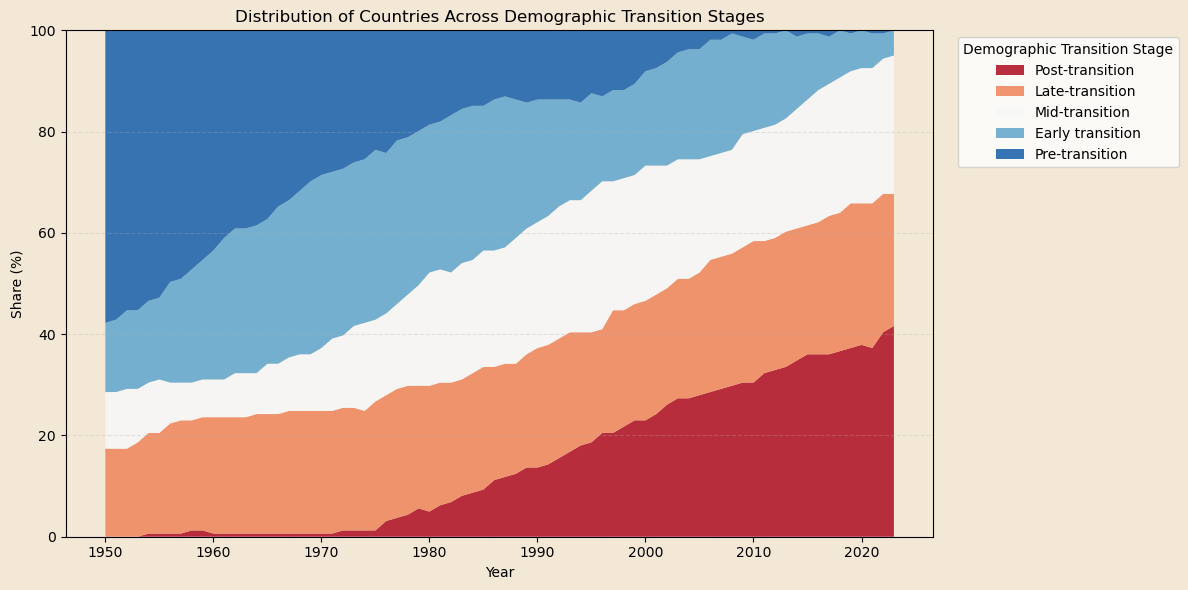

In [6]:
# Select measure
measure = "n_countries"  # Or "pop_millions"

df["cluster"] = pd.to_numeric(df["cluster"], errors="raise").astype(int)
df["year"] = pd.to_numeric(df["year"], errors="raise")
df[measure] = pd.to_numeric(df[measure], errors="coerce").fillna(0)

# Aggregate by numeric cluster ID
pivot = df.pivot_table(
    index="year",
    columns="cluster",
    values=measure,
    aggfunc="sum",
    fill_value=0
).reindex(columns=cluster_order, fill_value=0).sort_index()

# Convert to percentages
totals = pivot.sum(axis=1).replace(0, float("nan"))
shares = pivot.div(totals, axis=0).mul(100).fillna(0)

# Plot
fig, ax = plt.subplots(figsize=(12, 6))
fig.patch.set_facecolor("#F2E8D5")
ax.set_facecolor("#F2E8D5")

ax.stackplot(
    shares.index,
    *[shares[c].values for c in cluster_order],
    labels=[cluster_names[c] for c in cluster_order],
    colors=[cluster_colors[c] for c in cluster_order],
    alpha=0.9
)

ax.set_xlabel("Year")
ax.set_ylabel("Share (%)")

if measure == "n_countries":
    ax.set_title("Distribution of Countries Across Demographic Transition Stages")
else:
    ax.set_title("Population Share Across Demographic Transition Stages")

ax.set_ylim(0, 100)
ax.grid(axis="y", linestyle="--", alpha=0.3)

ax.legend(
    title="Demographic Transition Stage",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.savefig("../charts/g02_100_percent_stacked_area.png", dpi=300, bbox_inches="tight")
plt.show()